# Lab 4 · Course Navigator
## Notebook 1 — Learning from text with an RNN

In Modules 1–4, we connected predictions, loss and parameter updates, then learned how to run trustworthy experiments. Module 5 introduced embeddings and recurrent networks. Here we bring those ideas together around a useful application: helping a learner find the right course explanation.

**Key question:** How do words become numbers that a neural network can learn from?

### Learning objectives
- Define the product, labels and dataset before choosing a model.
- Explain tokenization, vocabulary, padding, embeddings, logits and cross-entropy.
- Trace a forward pass, gradients and an optimizer update through a real text model.
- Separate fitting, validation, testing and retrieval; inspect the RNN’s limitations.

### Classroom route and independent study

Plan about **25 minutes** for the guided route. Read the explanations, predict the output, then run each cell in order. Exercises and worked answers support a slower independent review. Saved results come from real CPU runs; seeds reduce variation but cannot guarantee identical numbers across machines.

### Setup

Use Python 3.12 in a dedicated environment. Download the **complete project ZIP** from the repository, extract it, install `requirements.txt`, and select that environment as your Jupyter kernel. In Colab, the first cell clones the project when needed. If imports fail, run `%pip install -r /content/course-navigator/requirements.txt` after that clone, restart the runtime and rerun from the top. Training needs no API key or paid service. The bundled base checkpoint permits offline model loading after dependencies are installed.

The default route loads supplied checkpoints. Set `RUN_TRAINING = True` to reproduce the full run into a separate classroom folder; the reference results remain unchanged. A notebook download alone does not contain its dataset and checkpoints.

In [1]:
from __future__ import annotations
from pathlib import Path
import sys, json, math, random, copy, time, re
from collections import Counter
from dataclasses import dataclass

# In Colab, clone the complete project once. Locally, open this notebook from
# the extracted project folder. A lone downloaded .ipynb has no model/data files.
ROOT = Path.cwd()
if not (ROOT / "coursenav").exists():
    if "google.colab" in sys.modules:
        import subprocess
        target = Path("/content/course-navigator")
        if not target.exists():
            subprocess.run(["git", "clone", "https://github.com/solomonpromise/course-navigator.git", str(target)], check=True)
        ROOT = target
    else:
        raise FileNotFoundError("Open this notebook inside the complete Course Navigator project folder; see README.md.")
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset, TensorDataset
from torch.nn.utils.rnn import pack_padded_sequence
from sklearn.feature_extraction.text import TfidfVectorizer
import warnings
# Optional progress widgets do not affect training.
warnings.filterwarnings("ignore", message="IProgress not found.*")
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
from IPython.display import display, Markdown
from coursenav.data import LABELS, MAX_LENGTH, words, encode, load_records, fit_vocabulary, TextDataset
from coursenav.training import (TrainConfig, seed_everything, fit, logits_for, summarize,
    dataset_for, load_reference, pretrained_tokenizer, pretrained_dataset, make_model)
seed_everything(42)
train, validation, test = (load_records(split) for split in ["train", "validation", "test"])
vocabulary = json.loads((ROOT / "artifacts/vocabulary.json").read_text())
results = json.loads((ROOT / "artifacts/results.json").read_text())["models"]
RUN_TRAINING = False  # True runs training; False loads the supplied measured checkpoint.
print("PyTorch:", torch.__version__, "| Device: CPU | Maximum tokens:", MAX_LENGTH)
print("Passages:", len(train), "train /", len(validation), "validation /", len(test), "test")

PyTorch: 2.14.1 | Device: CPU | Maximum tokens: 96
Passages: 1201 train / 286 validation / 265 test


## 1. Start with the product and the target

A learner writes “Why does my validation score get worse while training improves?” The app should suggest a topic, then link to relevant explanations. Our six **labels** are broad topic categories. A label is the answer supplied during supervised training; it is not something the model discovers without guidance.

The classifier produces six scores. A separate lexical search component selects actual passages and links. This distinction matters: a topic prediction is not an answer to the question. The app does not generate new explanations.

**Example** means one passage paired with a topic. **Feature** means information used to make a prediction. Here, features are learned from token sequences. **Inference** means applying fixed learned parameters to new input.

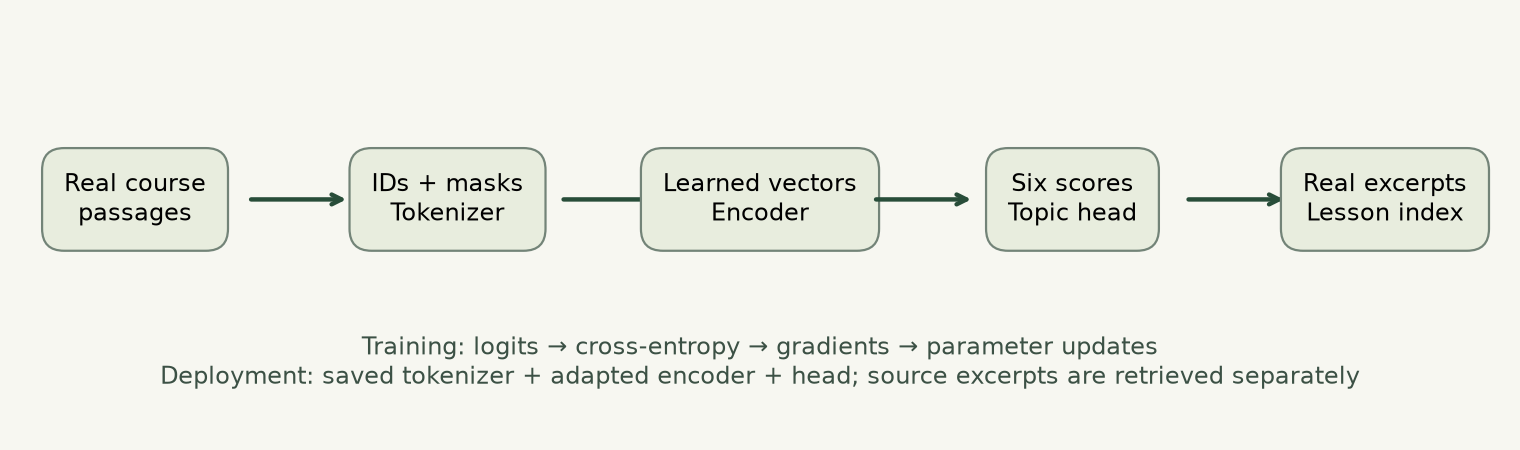

*The task head learns six course categories. Retrieved excerpts always come from the source library.*

In [2]:
display(pd.DataFrame({"label_id": range(len(LABELS)), "topic": LABELS}))
example = train[0]
print(example["text"])
print("Label:", LABELS[example["label"]], "| Source:", example["url"])

,label_id,topic
0,0,Foundations & PyTorch
1,1,Training & evaluation
2,2,Representations & sequences
3,3,Transformers & attention
4,4,Pretrained applications
5,5,Model adaptation


You arrive at this course already able to do a great deal. You can load a messy dataset, clean it, explore it, encode categoricals, split it properly, fit a model, tune it, and evaluate it honestly. That is not a small skill set. Most of what follows depends on it. So it is worth being precise about what is actually new here, because the honest answer is narrower than the marketing suggests. In everything you have built so far, you decided what the model would look at. You chose the
Label: Foundations & PyTorch | Source: https://solomonpromise.github.io/deep-learning-lab/module-1/lesson-1-1.html#s1


## 2. Real data, provenance and the split contract

The dataset contains **1,752 real prose passages from 337 sections** in Modules 1–8. It was extracted from the published notebooks at the Git revision recorded below. Code cells, outputs and setup sections are excluded. Text is cleaned, then divided into non-overlapping windows. A short final window is omitted when it contains fewer than 25 scratch-tokenizer words.

All windows from one section stay together. Otherwise two pieces of the same explanation could inflate apparent generalization. There are **1,201 training, 286 validation and 265 test passages**. Sections from the same lesson can still occur in different splits; this is evaluation on new sections within a known course, not new courses.

The 36 additional question probes are **authored teaching examples**, not collected learner questions. They were frozen before training and excluded from fitting, checkpoint selection and confidence-policy tuning. They help expose the gap between training on passages and receiving short questions. They are too small to establish real-world reliability.

**Data leakage** means information that should be unavailable during learning influences training or selection. Fitting a vocabulary on test text is a subtle example. Indexing all published sections for later search is a different operation: those sections are the app’s public reference library, not labels used to fit the classifier.

In [3]:
manifest = json.loads((ROOT / "data/manifest.json").read_text())
print("Source revision:", manifest["source_revision"])
groups = [{row["group"] for row in rows} for rows in [train, validation, test]]
assert not groups[0] & groups[1] and not groups[0] & groups[2] and not groups[1] & groups[2]
all_rows = train + validation + test
assert len({row["text_sha256"] for row in all_rows}) == len(all_rows)
display(pd.crosstab(pd.Series([LABELS[r["label"]] for r in all_rows], name="Topic"),
                    pd.Series([r["split"] for r in all_rows], name="Split")))

Source revision: 2928128b004b1113e044fb7ff1894d8b0b59ea54


Split,test,train,validation
Topic,,,
Foundations & PyTorch,71,222,46
Model adaptation,36,155,36
Pretrained applications,30,221,59
Representations & sequences,38,178,47
Training & evaluation,64,282,65
Transformers & attention,26,143,33


## 3. A baseline earns its place

Before building a neural network, we train a **TF-IDF + logistic regression** baseline. TF measures how often a term appears in a passage; IDF reduces the influence of terms common across the training collection. Logistic regression learns a linear decision rule on those features. It is a trained model too.

Our baseline fits its vocabulary and IDF using training rows only. Its settings were fixed before final evaluation. A strong baseline protects us from confusing complexity with progress. The saved comparison later shows that this baseline beats our fine-tuned encoder on passage macro-F1 in this reference run.

In [4]:
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

baseline = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), max_features=12000, sublinear_tf=True),
    LogisticRegression(C=2.0, class_weight="balanced", max_iter=1000, random_state=42),
)
baseline.fit([row["text"] for row in train], [row["label"] for row in train])
valid_predictions = baseline.predict_proba([row["text"] for row in validation])
print("Baseline validation macro-F1:", summarize([r["label"] for r in validation], valid_predictions)["macro_f1"])

Baseline validation macro-F1: 0.7914984655749994


## 4. Token IDs are addresses, not meanings

**Tokenization** divides text into units. Our scratch tokenizer lowercases and retains word/number patterns. “Attention learns!” becomes `['attention', 'learns']`. This loses punctuation and case; every preprocessing choice carries a trade-off.

A **vocabulary** maps tokens to integer IDs. ID 47 is not inherently more meaningful than ID 3. `[PAD]` fills unused positions; `[UNK]` represents a real token absent from the training vocabulary. Only training passages establish the vocabulary. Validation and test examples are encoded with that fixed mapping.

We cap inputs at 96 scratch tokens to control compute. **Truncation** drops later tokens. **Padding** fills shorter inputs; a true-length tensor tells recurrence where each sequence ends. The deployed pretrained model has its own tokenizer and reserves two of its 96 positions for special tokens.

In [5]:
def words(text: str) -> list[str]:
    """Lowercase text and retain words/numbers; this is our scratch tokenizer.

    This simple rule is intentionally different from BERT's WordPiece tokenizer.
    Never substitute one model's tokenizer for another model's tokenizer.
    """
    return re.findall(r"[a-z0-9]+(?:'[a-z]+)?", text.lower())

def fit_vocabulary(rows: list[dict], limit: int = 6000) -> dict[str, int]:
    """Fit word IDs on training rows only, reserving 0 for PAD and 1 for UNK.

    PAD means 'no real token here'; UNK means 'a real word absent from training'.
    A deterministic frequency/name ordering makes the artifact reproducible.
    """
    if any(row["split"] != "train" for row in rows):
        raise ValueError("Vocabulary fitting accepts training rows only")
    counts = Counter(word for row in rows for word in words(row["text"]))
    ordered = sorted(counts, key=lambda word: (-counts[word], word))[:limit - 2]
    return {"[PAD]": 0, "[UNK]": 1, **{word: i + 2 for i, word in enumerate(ordered)}}

def encode(text: str, vocabulary: dict, max_length: int = MAX_LENGTH) -> tuple[list[int], int]:
    """Return padded IDs and the real length, truncating overly long passages.

    Empty input becomes one UNK token so packed recurrence and masked means
    remain mathematically defined. The public app rejects blank input earlier.
    """
    ids = [vocabulary.get(word, 1) for word in words(text)][:max_length] or [1]
    length = len(ids)
    return ids + [0] * (max_length - length), length

In [6]:
assert fit_vocabulary(train) == vocabulary
text = "Attention learns useful relationships between tokens."
ids, length = encode(text, vocabulary)
print("Words:", words(text))
print("IDs:", ids[:length], "| Real length:", length)
print("Padding positions:", len(ids) - length)
unknown_fraction = np.mean([word not in vocabulary for row in validation for word in words(row["text"])])
print("Validation unknown-word fraction:", round(float(unknown_fraction), 3))

Words: ['attention', 'learns', 'useful', 'relationships', 'between', 'tokens']
IDs: [133, 527, 174, 2922, 151, 77] | Real length: 6
Padding positions: 90
Validation unknown-word fraction: 0.025


## 5. Embeddings are learned rows

An **embedding table** is a parameter matrix with one row per vocabulary entry. Looking up a token ID selects its row. The row begins as random numbers for our scratch models. Backpropagation adjusts rows used by training examples so that their downstream predictions improve.

If the vocabulary has V entries and each vector has D components, the matrix has V × D parameters. A batch of IDs shaped `(B, T)` becomes vectors shaped `(B, T, D)`. B is the number of examples; T is the number of time steps; D is the embedding width.

Unlike a pretrained language encoder, these embeddings see only this small course corpus. Similarity in a two-dimensional projection is an illustration, not proof of general language understanding.

In [7]:
embedding = nn.Embedding(len(vocabulary), 64, padding_idx=0)
sample_ids = torch.tensor([ids], dtype=torch.long)
print("Table:", tuple(embedding.weight.shape))
print("Batch of vectors:", tuple(embedding(sample_ids).shape))
print("Trainable table entries:", embedding.weight.numel())

Table: (5894, 64)
Batch of vectors: (1, 96, 64)
Trainable table entries: 377216


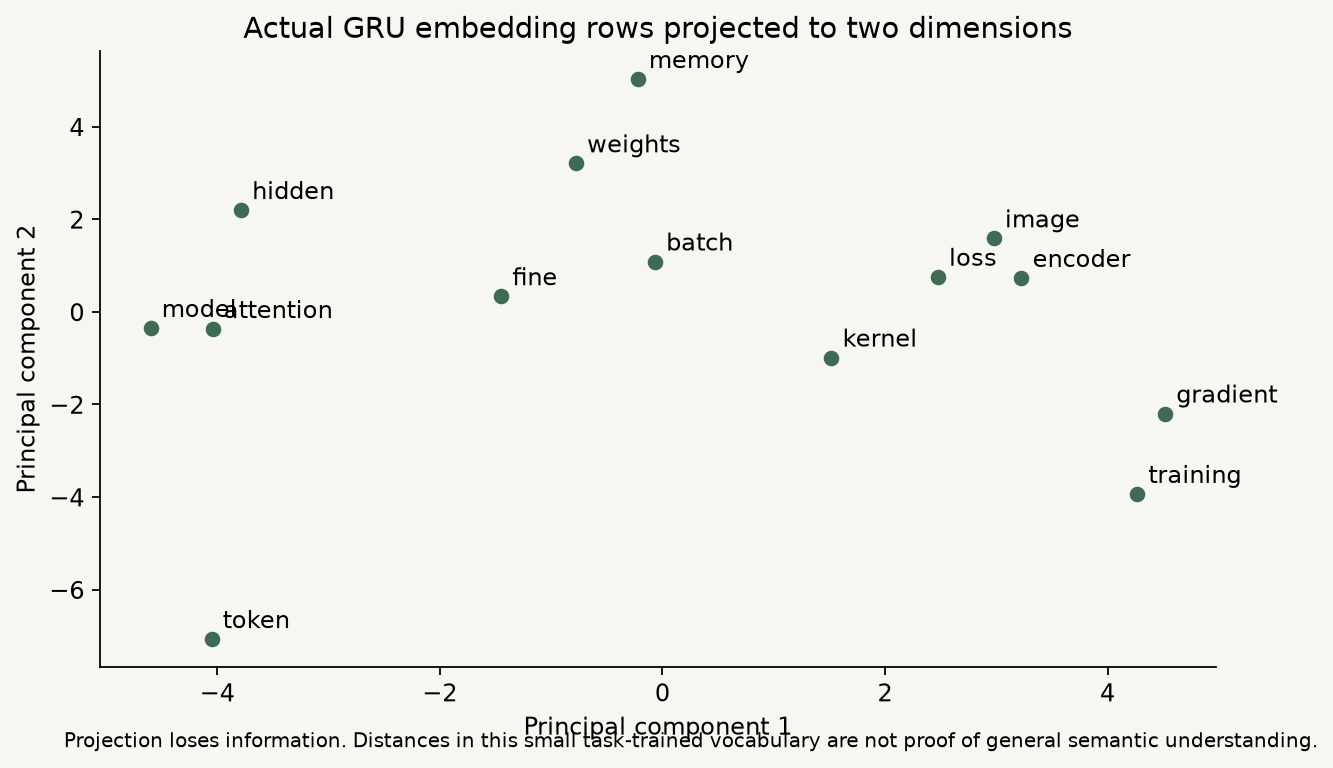

*These are measured embedding vectors from Notebook 2’s saved GRU. Projection discards information.*

## 6. Read the sequence with a recurrent state

An RNN repeatedly applies the same update:

$$h_t=\tanh(W_xx_t+W_hh_{t-1}+b).$$

The **hidden state** is a vector carrying information forward. Parameter sharing means the same matrices operate at every time step. Earlier words can influence later states through the chain of updates. A final linear **head** converts the last valid state into six topic logits.

We use packed sequences so padding does not become extra fake words. PyTorch handles the recurrent loop efficiently; the mathematical operation remains the update above. This is a unidirectional, one-layer baseline. Its weaknesses do not establish that every recurrent architecture is unsuitable for text.

In [8]:
class RecurrentClassifier(nn.Module):
    """Learn word embeddings, read a sequence and classify its final state.

    Args:
        vocabulary_size: Number of train-fitted word IDs, including PAD/UNK.
        kind: RNN, LSTM or GRU; the rest of the pipeline stays identical.
        width: Embedding and hidden-state dimensions in this classroom model.

    Packing removes padding steps. Without it, a 'final state' could describe
    several padding tokens rather than the end of the learner's sentence.
    """
    def __init__(self, vocabulary_size: int, kind: str = "RNN", width: int = 64):
        super().__init__()
        if kind not in {"RNN", "LSTM", "GRU"}:
            raise ValueError("Choose RNN, LSTM or GRU")
        self.kind = kind
        self.embedding = nn.Embedding(vocabulary_size, width, padding_idx=0)
        self.recurrent = getattr(nn, kind)(width, width, batch_first=True)
        self.dropout = nn.Dropout(0.15)
        self.head = nn.Linear(width, len(LABELS))

    def forward(self, ids: torch.Tensor, lengths: torch.Tensor) -> torch.Tensor:
        embedded = self.embedding(ids)  # (B,T) -> (B,T,D)
        packed = pack_padded_sequence(embedded, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, state = self.recurrent(packed)
        # LSTM returns (hidden state, cell state); classification uses hidden.
        hidden = state[0] if self.kind == "LSTM" else state
        return self.head(self.dropout(hidden[-1]))  # (B,D) -> (B,C)

In [9]:
seed_everything()
rnn = RecurrentClassifier(len(vocabulary), kind="RNN")
batch = next(iter(DataLoader(TextDataset(train, vocabulary), batch_size=8)))
batch_ids, lengths, targets = batch
logits = rnn(batch_ids, lengths)
print("IDs:", tuple(batch_ids.shape), "Lengths:", tuple(lengths.shape))
print("Logits:", tuple(logits.shape), "Targets:", targets.tolist())
assert logits.shape == (8, len(LABELS))

IDs: (8, 96) Lengths: (8,)
Logits: (8, 6) Targets: [0, 0, 0, 0, 0, 0, 0, 0]


## 7. Loss gives learning a direction

A **logit** is an unrestricted score. Softmax converts six logits into positive numbers summing to one. For a correct label y, cross-entropy is $-\log p_y$. Assigning little probability to the true label produces a large loss.

`CrossEntropyLoss` combines log-softmax and negative log likelihood in a numerically stable operation. Pass raw logits to it. Applying softmax first changes the calculation and loses numerical stability.

`backward()` computes derivatives, not updated weights. A **gradient** tells us how the loss would change for a small parameter change. The optimizer performs the update. AdamW maintains moving gradient statistics and applies decoupled weight decay; its learning rate controls the scale of those updates.

In [10]:
toy_logits = torch.tensor([[1.2, -0.3, 0.4, 0.1, -0.5, 0.2]])
toy_target = torch.tensor([0])
probabilities = toy_logits.softmax(-1)
manual_loss = -probabilities[0, 0].log()
library_loss = nn.functional.cross_entropy(toy_logits, toy_target)
print("Probabilities:", probabilities.numpy().round(3))
print("Manual / stable library loss:", manual_loss.item(), library_loss.item())
assert torch.allclose(manual_loss, library_loss)

Probabilities: [[0.391 0.087 0.176 0.13  0.071 0.144]]
Manual / stable library loss: 0.9384016394615173 0.9384016394615173


## 8. Watch one actual parameter update

This demonstration uses an independent model copy, so it cannot corrupt the supplied reference checkpoint. We clear old gradients, compute logits and loss, backpropagate, inspect a gradient, clip its norm and update parameters. Clipping limits exploding updates; it does not solve vanishing gradients.

Predict first: after `backward()`, have the weights already changed? The answer is no. After `step()`, they should change if their gradient is nonzero.

In [11]:
demo = copy.deepcopy(rnn)
optimizer = torch.optim.AdamW(demo.parameters(), lr=0.002, weight_decay=0.01)
before = demo.head.weight.detach().clone()
optimizer.zero_grad(set_to_none=True)
loss = nn.functional.cross_entropy(demo(batch_ids, lengths), targets)
loss.backward()
print("Head gradient norm:", float(demo.head.weight.grad.norm()))
assert torch.equal(before, demo.head.weight.detach())
torch.nn.utils.clip_grad_norm_(demo.parameters(), max_norm=1.0)
optimizer.step()
print("Largest head-weight change:", float((demo.head.weight.detach()-before).abs().max()))

Head gradient norm: 1.4589039087295532
Largest head-weight change: 0.0020024701952934265


## 9. The complete training loop, with validation checkpoints

An **epoch** is one pass through the training rows. A **minibatch** supplies one noisy loss estimate. We rebalance cross-entropy using training class counts, shuffle training batches with a seeded generator, and retain the epoch with the highest validation macro-F1.

**Precision** asks how often predictions for a class are correct. **Recall** asks how many true examples of that class were found. **F1** combines precision and recall. **Macro-F1** computes F1 separately for each topic, then averages, giving each topic equal weight.

`model.train()` enables dropout; `model.eval()` disables it. `inference_mode()` disables gradient tracking during evaluation. These solve different problems. Early stopping uses validation, never test performance. Read this loop slowly: it is the learning mechanism from Module 2 applied to language.

In [12]:
@dataclass
class TrainConfig:
    """Fixed reference settings; test labels never influence these choices."""
    seed: int = 42
    batch_size: int = 32
    epochs: int = 20
    patience: int = 5
    learning_rate: float = .002
    weight_decay: float = .01
    max_grad_norm: float = 1.

@torch.inference_mode()
def logits_for(model, dataset, batch_size=64):
    """Disable dropout/gradients and preserve row order during inference."""
    model.eval()
    return torch.cat([model(*batch[:-1]).cpu() for batch in DataLoader(dataset, batch_size=batch_size)])

def summarize(labels, logits):
    """Report accuracy, macro-F1 and per-class errors; no metric is fabricated."""
    predictions = np.asarray(logits).argmax(axis=1)
    return dict(accuracy=float(accuracy_score(labels, predictions)),
                macro_f1=float(f1_score(labels, predictions, labels=range(len(LABELS)), average="macro", zero_division=0)),
                confusion_matrix=confusion_matrix(labels, predictions, labels=range(len(LABELS))).tolist(),
                classification_report=classification_report(labels, predictions, labels=range(len(LABELS)),
                                                            target_names=LABELS, output_dict=True, zero_division=0))

def fit(model, train_data, validation_data, config: TrainConfig, frozen=False):
    """Train with AdamW; retain the checkpoint with the best validation macro-F1.

    Returns the restored best model, per-epoch measurements and elapsed seconds.
    This function accepts no test dataset: selection cannot accidentally use it.
    """
    generator = torch.Generator().manual_seed(config.seed)
    batches = DataLoader(train_data, batch_size=config.batch_size, shuffle=True, generator=generator)
    counts = torch.bincount(train_data.tensors[-1] if hasattr(train_data, "tensors") else train_data.labels,
                            minlength=len(LABELS)).float()
    class_weights = len(train_data) / (len(LABELS) * counts.clamp_min(1))
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],
                                  lr=config.learning_rate, weight_decay=config.weight_decay)
    best_score, best_epoch, best_state, history = -1., 0, None, []
    started = time.perf_counter()
    for epoch in range(1, config.epochs + 1):
        model.train()
        if frozen:
            model.encoder.eval()  # frozen features should not randomly change through dropout
        total_loss, examples = 0., 0
        for batch in batches:
            # 1 clear accumulated gradients; 2 forward; 3 loss; 4 backward; 5 update.
            optimizer.zero_grad(set_to_none=True)
            logits = model(*batch[:-1])
            loss = criterion(logits, batch[-1])
            loss.backward()
            # Clipping limits an unstable update; it does not cure vanishing gradients.
            nn.utils.clip_grad_norm_(model.parameters(), config.max_grad_norm)
            optimizer.step()
            total_loss += loss.item() * len(batch[-1])
            examples += len(batch[-1])
        valid_logits = logits_for(model, validation_data)
        labels = validation_data.tensors[-1].numpy() if hasattr(validation_data, "tensors") else validation_data.labels.numpy()
        scores = summarize(labels, valid_logits.numpy())
        entry = dict(epoch=epoch, train_loss=total_loss/examples, validation_macro_f1=scores["macro_f1"],
                     validation_loss=float(nn.functional.cross_entropy(valid_logits, torch.tensor(labels))))
        history.append(entry)
        print(f"epoch={epoch:02d} loss={entry['train_loss']:.3f} val_f1={entry['validation_macro_f1']:.3f}", flush=True)
        if scores["macro_f1"] > best_score + 1e-5:
            best_score, best_epoch = scores["macro_f1"], epoch
            best_state = copy.deepcopy(model.state_dict())
        if epoch - best_epoch >= config.patience:
            break
    model.load_state_dict(best_state)
    model.eval()
    return model, history, time.perf_counter() - started

In [13]:
if RUN_TRAINING:
    seed_everything()
    rnn, history, seconds = fit(RecurrentClassifier(len(vocabulary), "RNN"),
        TextDataset(train, vocabulary), TextDataset(validation, vocabulary), TrainConfig())
    output = ROOT / "artifacts/classroom"
    output.mkdir(exist_ok=True)
    torch.save(rnn.state_dict(), output / "rnn.pt")
else:
    rnn.load_state_dict(torch.load(ROOT / "artifacts/rnn.pt", map_location="cpu", weights_only=True))
    history = next(row for row in results if row["name"] == "rnn")["history"]
rnn.eval()
display(pd.DataFrame(history).tail())

,epoch,train_loss,validation_macro_f1,validation_loss
15,16,0.050950,0.242042,3.471688
16,17,0.029396,0.268378,3.354179
17,18,0.021632,0.278661,3.403012
18,19,0.018036,0.269717,3.617571
19,20,0.014944,0.255122,3.776558


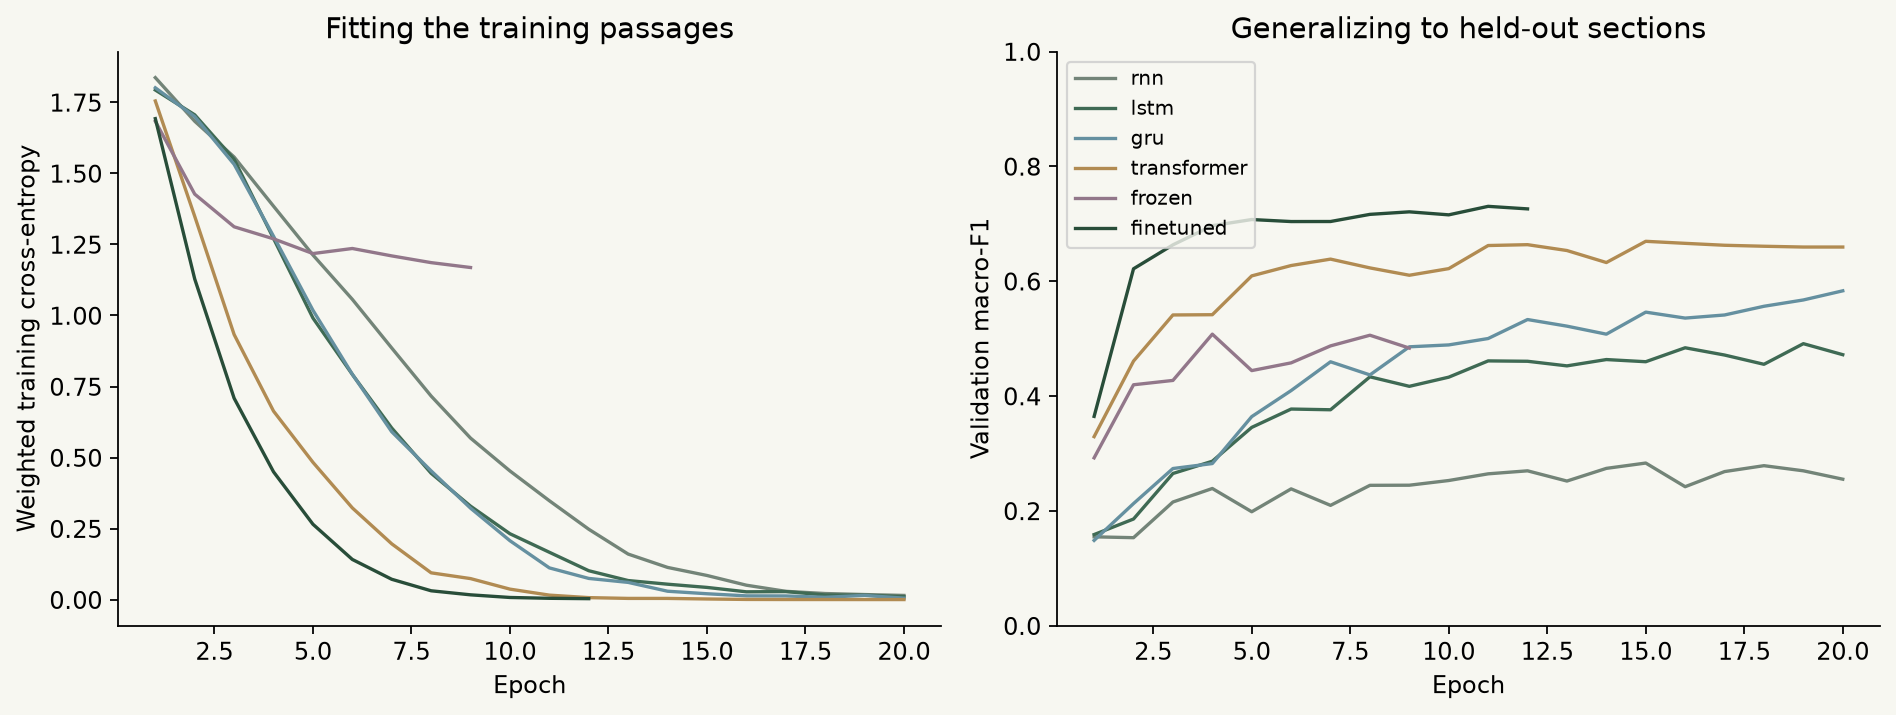

*The reference curves are measurements, not expected values to force a new run to match.*

## 10. Read the result without overclaiming

The saved RNN’s passage test macro-F1 is about **0.285**, and it answers 8 of 36 authored topic probes correctly. That is weak for a six-topic routing task. Its training loss falls much further than its validation performance improves, warning us about limited generalization.

Possible contributors include the small dataset, a final-state bottleneck, long sequences, initialization and this training configuration. These results alone do not isolate which cause dominates. We did not tune on the test set to make the RNN look better. Notebook 2 investigates architectures designed to manage state more carefully.

In [14]:
row = next(row for row in results if row["name"] == "rnn")
display(pd.DataFrame(row["test"]["classification_report"]).T)
probe = "Why does a model need an activation function?"
encoded, length = encode(probe, vocabulary)
with torch.inference_mode():
    probability = rnn(torch.tensor([encoded]), torch.tensor([length])).softmax(-1)[0]
display(pd.Series(probability.numpy(), index=LABELS).sort_values(ascending=False))

,precision,recall,f1-score,support
Foundations & PyTorch,0.459016,0.394366,0.424242,71.000000
Training & evaluation,0.360000,0.421875,0.388489,64.000000
Representations & sequences,0.228571,0.210526,0.219178,38.000000
Transformers & attention,0.240000,0.230769,0.235294,26.000000
Pretrained applications,0.200000,0.266667,0.228571,30.000000
Model adaptation,0.241379,0.194444,0.215385,36.000000
accuracy,0.316981,0.316981,0.316981,0.316981
macro avg,0.288161,0.286441,0.285193,265.000000
weighted avg,0.321681,0.316981,0.317139,265.000000


Transformers & attention       0.515695
Training & evaluation          0.455957
Foundations & PyTorch          0.026641
Pretrained applications        0.000867
Model adaptation               0.000482
Representations & sequences    0.000358
dtype: float32

## 11. Try it, then check your reasoning

1. Predict the effect of replacing every word with `[UNK]`. Test on a copy of an encoded batch. Why can the network still emit a confident score?
2. Change 96 to a smaller maximum length in an isolated experiment. What training cost and information-loss trade-offs should you measure?
3. Why does rebuilding the vocabulary after loading a checkpoint break the model even when its shape stays the same?
4. Why is a question-probe score different from performance on actual learners?

<details><summary>Worked answers</summary>

1. Topic-specific word evidence disappears; position, length and biases can still drive logits. Confidence is not a proof of understanding.
2. Shorter inputs reduce recurrent steps and memory, but may remove decisive context. Refit on training, select on validation, and reserve a new test for repeated development.
3. Rows now refer to different words. Weight shapes are only part of the inference contract; the exact ID mapping matters.
4. Authored questions are small, curated and may differ from real spelling, ambiguity, language and topic frequencies. A representative evaluation needs consented real inputs and a separate protocol.

</details>

**Next:** [Notebook 2 — LSTM and GRU](02_lstm_gru.ipynb). Keep the same data and labels; change how information moves through time.